## 1. Tokenization

In [232]:
import tiktoken
tokenizer = tiktoken.get_encoding('gpt2')

In [233]:
text = "I am doing excellent"
enc_ids = tokenizer.encode(text)
print(f"Encoded : {enc_ids}")

dec_text = tokenizer.decode(enc_ids)
print(f"Decoded : {dec_text}")

Encoded : [40, 716, 1804, 6275]
Decoded : I am doing excellent


### 1.1 Tokens of mispelled words

In [234]:
# Unknown words are handled better through BPE : Splitting into known subwords
text = "I am doing excaellent"
enc_ids = tokenizer.encode(text)
dec_text = tokenizer.decode(enc_ids)

print(f"Encoded : {enc_ids}")
print(f"Decoded : {dec_text}")

print("Decoded Step by step : ")
for id in enc_ids:
    sub_word = tokenizer.decode([id])
    print(sub_word)

Encoded : [40, 716, 1804, 2859, 64, 695, 298]
Decoded : I am doing excaellent
Decoded Step by step : 
I
 am
 doing
 exc
a
ell
ent


## 2. Data Loaders & Sequencing

1. Same-length input and target (ex : input size = 1, max_length = output size)
2. Shifted by one token
3. All positions predicted in parallel
4. One next-token loss per position.

In [235]:
# Dataloaders & sequencing

text = "I am going to office"
max_length = 4

# Conceptually:
input_tokens  = ["I",  "am",    "going", "to"]
target_tokens = ["am", "going", "to",    "office"]

# Each position performs next-token prediction:
# "I"              -> "am"
# "I am"           -> "going"
# "I am going"     -> "to"
# "I am going to"  -> "office"

# Loss = CE(pred_1, "am") + CE(pred_2, "going") + CE(pred_3, "to") + CE(pred_4, "office")

# NOT just: input = ["I", "am", "going", "to"] -> target = ["office"]

# Causal masking prevents each position from seeing future tokens. predicting going, for example, the model can see [I, am]

token_ids = tokenizer.encode(text)

i = 0
input_chunk = token_ids[i : i + max_length]
target_chunk = token_ids[i + 1 : i + max_length + 1]

print("Token IDs:", token_ids)
print("Input IDs:", input_chunk)
print("Target IDs:", target_chunk)

print("Input:", tokenizer.decode(input_chunk))
print("Target:", tokenizer.decode(target_chunk))

Token IDs: [40, 716, 1016, 284, 2607]
Input IDs: [40, 716, 1016, 284]
Target IDs: [716, 1016, 284, 2607]
Input: I am going to
Target:  am going to office


## 3. Embedding

In [236]:
import torch.nn as nn
import torch

input_tensor = torch.tensor([2, 1, 0, 3])
context_length = len(input_tensor)
emb_dim=5

In [237]:
# Input Embedding
vocab_size = 1000
token_embedding_layer = nn.Embedding(vocab_size, emb_dim)
token_embedding = token_embedding_layer(input_tensor)
token_embedding.shape

torch.Size([4, 5])

In [238]:
# Positional Embedding
pos_embedding_layer = nn.Embedding(max_length, emb_dim)
pos_embedding = pos_embedding_layer(input_tensor)
pos_embedding.shape

torch.Size([4, 5])

In [239]:
input_embedding = token_embedding + pos_embedding
input_embedding.shape

torch.Size([4, 5])

In [240]:
input_embedding

tensor([[ 1.1796,  3.8681,  0.5880,  1.8795, -0.0796],
        [ 1.6026,  0.5768,  0.5981, -0.0211,  0.2857],
        [-0.2053,  1.9384,  1.3103,  1.9406,  2.3067],
        [ 1.7801,  1.8026,  1.8310,  0.8092,  1.3957]], grad_fn=<AddBackward0>)

## 4. Attention

In [241]:
Wk = nn.Linear(emb_dim, emb_dim) # 5, 5
Wq = nn.Linear(emb_dim, emb_dim)
Wv = nn.Linear(emb_dim, emb_dim)

k = Wk(input_embedding) # 4, 5
q = Wq(input_embedding)
v = Wv(input_embedding)

attn_score = q @ k.T  # 4, 4
attn_weight = torch.softmax(attn_score, dim=-1)
context_vector = attn_weight@v  # 4, 5
attn_weight

tensor([[0.0195, 0.5582, 0.1489, 0.2735],
        [0.0983, 0.3285, 0.2983, 0.2749],
        [0.0349, 0.4094, 0.3242, 0.2315],
        [0.0321, 0.3487, 0.3394, 0.2799]], grad_fn=<SoftmaxBackward0>)

In [242]:
mask = torch.triu(torch.ones(context_length, context_length), diagonal=1)
masked = attn_weight.masked_fill(mask.bool(), -torch.inf)
masked_norm = torch.softmax(masked, dim=-1)
masked_norm

tensor([[1.0000, 0.0000, 0.0000, 0.0000],
        [0.4427, 0.5573, 0.0000, 0.0000],
        [0.2639, 0.3837, 0.3524, 0.0000],
        [0.1995, 0.2738, 0.2712, 0.2556]], grad_fn=<SoftmaxBackward0>)

In [243]:
context_vector = masked_norm@v  # 4, 5
context_vector

tensor([[ 0.7324,  1.8413,  1.7312, -1.7353, -0.2276],
        [ 0.6490,  0.6981,  0.6393, -1.2272, -0.0144],
        [ 0.4535,  1.3756,  0.9915, -1.3424,  0.2116],
        [ 0.5256,  1.3648,  1.0177, -1.3843,  0.3687]], grad_fn=<MmBackward0>)

In [244]:
batch_inputs = torch.stack((input_embedding, input_embedding)) # 2, 4, 5
print(batch_inputs.shape)

Wk = nn.Linear(emb_dim, emb_dim)   # 5, 5
Wq = nn.Linear(emb_dim, emb_dim)
Wv = nn.Linear(emb_dim, emb_dim)

k = Wk(batch_inputs) # 2, 4, 5
q = Wq(batch_inputs)
v = Wv(batch_inputs)

print(q.shape, k.shape)
attn_scores = q @ k.transpose(-2, -1) # 2, 4, 4
attn_weights = torch.softmax(attn_scores, dim=-1)
print(attn_weights.shape)

mask = torch.triu(torch.ones(context_length, context_length), diagonal=1)
masked = attn_weights.masked_fill(mask.bool(), -torch.inf)
attn_masked_norm = torch.softmax(masked, dim=-1)
print(attn_masked_norm)
context_vector = attn_masked_norm @ v
print(context_vector.shape) # 2, 4, 5

torch.Size([2, 4, 5])
torch.Size([2, 4, 5]) torch.Size([2, 4, 5])
torch.Size([2, 4, 4])
tensor([[[1.0000, 0.0000, 0.0000, 0.0000],
         [0.4871, 0.5129, 0.0000, 0.0000],
         [0.3686, 0.3155, 0.3159, 0.0000],
         [0.2417, 0.2616, 0.2243, 0.2725]],

        [[1.0000, 0.0000, 0.0000, 0.0000],
         [0.4871, 0.5129, 0.0000, 0.0000],
         [0.3686, 0.3155, 0.3159, 0.0000],
         [0.2417, 0.2616, 0.2243, 0.2725]]], grad_fn=<SoftmaxBackward0>)
torch.Size([2, 4, 5])


### Multi Head Attention

In [245]:
emb_dim = 10 # this is to split heads equally : emb_dim // num_heads
input_embedding_layer = nn.Embedding(vocab_size, emb_dim)
input_embedding = input_embedding_layer(input_tensor)
print(input_embedding.shape)
## now 10 is divisble by 2 heads

torch.Size([4, 10])


In [246]:
batch_inputs = torch.stack((input_embedding, input_embedding)) # 2, 4, 10
print(batch_inputs.shape)

num_heads = 2
head_dim = emb_dim // 2
Wk = nn.Linear(emb_dim, emb_dim) # 10, 10
Wq = nn.Linear(emb_dim, emb_dim)
Wv = nn.Linear(emb_dim, emb_dim)

k = Wk(batch_inputs) # 2, 4, 10
q = Wq(batch_inputs)
v = Wv(batch_inputs)

k_split = k.view(2, max_length, num_heads, head_dim) # 2, 4, 2, 5
q_split = q.view(2, max_length, num_heads, head_dim)
v_split = v.view(2, max_length, num_heads, head_dim)

k_final = k_split.transpose(1, 2) # 2, 2, 4, 5
q_final = q_split.transpose(1, 2)
v_final = v_split.transpose(1, 2)

attn_score = q_final @ k_final.transpose(-2, -1) # 2, 2, 4, 4

mask = torch.triu(torch.ones(context_length, context_length), diagonal=1)
masked = attn_score.masked_fill(mask.bool(), -torch.inf)
attn_weights_masked = torch.softmax(masked, dim=-1)

context_vector = attn_weights_masked @ v_final # 2, 2, 4, 5
context_vector = context_vector.contiguous().view(2, max_length, emb_dim) # 2, 4, 10

Wo = nn.Linear(emb_dim, emb_dim) # 10, 10
output = Wo(context_vector) # 2, 4, 10
output.shape

torch.Size([2, 4, 10])


torch.Size([2, 4, 10])

## 5. Normalization

1. Ensure stable training
2. Enabled the weights are similar range and speeds convergence

In [247]:
input = torch.randn((2, 4))
mean = torch.mean(input, dim=-1, keepdim=True) # this ensures we can : x - mean; otherwise it will reduce and throw dim error
var = torch.var(input, dim=-1, keepdim=True)
print(f"Mean : {mean}")
print(f"Variance : {var}")

Mean : tensor([[1.0169],
        [0.5985]])
Variance : tensor([[1.3921],
        [0.5265]])


In [248]:
input_norm = (input - mean)/torch.sqrt(var)
mean = torch.mean(input_norm, dim=-1)
var = torch.var(input_norm, dim=-1)
print(f"Mean : {mean}")
print(f"Variance : {var}")

Mean : tensor([ 5.9605e-08, -2.9802e-08])
Variance : tensor([1.0000, 1.0000])


## 6. Skip Connections

1. In very big networks and layers, gradients get vanished in reaching earlier layers. 
2. To ensure, smooth flow of gradients alternate paths are added - skip connections

In [249]:
# without skip connections and check gradients

ffn = nn.Sequential(
    nn.Linear(10, 20),
    nn.ReLU(),
    nn.Linear(20, 20),
    nn.ReLU(),
    nn.Linear(20, 20),
    nn.ReLU(),
    nn.Linear(20, 20),
    nn.ReLU(),
    nn.Linear(20, 20),
    nn.ReLU(),
    nn.Linear(20, 1)
)
input = torch.randn((1, 10))
target = torch.tensor([1.0])
output = ffn(input)

loss = nn.MSELoss()
loss = loss(output, target)

loss.backward()

for name, param in ffn.named_parameters():
    if 'weight' in name:
        print(f"{name} has gradient mean of {param.grad.abs().mean().item()}")

# gradients getting smaller from last layer to first layer

0.weight has gradient mean of 0.001653797458857298
2.weight has gradient mean of 0.001089323777705431
4.weight has gradient mean of 0.001198041019961238
6.weight has gradient mean of 0.0018268106505274773
8.weight has gradient mean of 0.0052535091526806355
10.weight has gradient mean of 0.17890413105487823


C:\Users\rpandur\rangarajp.github.io-1\.venv-qwen\Lib\site-packages\torch\nn\modules\loss.py:630: UserWarning: Using a target size (torch.Size([1])) that is different to the input size (torch.Size([1, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


In [250]:
class SimpleNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.layer1 = nn.Linear(10, 20)
        self.layer2 = nn.Linear(20, 20)
        self.layer3 = nn.Linear(20, 20)
        self.layer4 = nn.Linear(20, 20)
        self.layer5 = nn.Linear(20, 20)
        self.layer6 = nn.Linear(20, 1)

        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.layer1(x))   
        skip = x                        # Save for skip 
        x = x + skip                    # Skip connection B, 20

        x = self.relu(self.layer2(x))   
        x = x + skip                    # Skip connection B, 20

        x = self.relu(self.layer3(x))   
        x = x + skip                    # Skip connection B, 20

        x = self.relu(self.layer4(x))   
        x = x + skip                    # Skip connection B, 20

        x = self.relu(self.layer5(x))   
        x = x + skip                    # Skip connection B, 20

        x = self.layer6(x)              
        return x

ffn_skip = SimpleNN()

input = torch.randn((1, 10))
target = torch.tensor([1.0])
output = ffn_skip(input)

loss = nn.MSELoss()
loss = loss(output, target)

loss.backward()

for name, param in ffn_skip.named_parameters():
    if 'weight' in name:
        print(f"{name} has gradient mean of {param.grad.abs().mean().item()}")

layer1.weight has gradient mean of 0.06323068588972092
layer2.weight has gradient mean of 0.0029128966853022575
layer3.weight has gradient mean of 0.005361029878258705
layer4.weight has gradient mean of 0.011218040250241756
layer5.weight has gradient mean of 0.02334931120276451
layer6.weight has gradient mean of 0.6915863156318665


## 7 Loss Function  : Cross Entropy

Measures how similar are the two distributions
Cross Entropy uses probabilities and not logits coming from linear layer

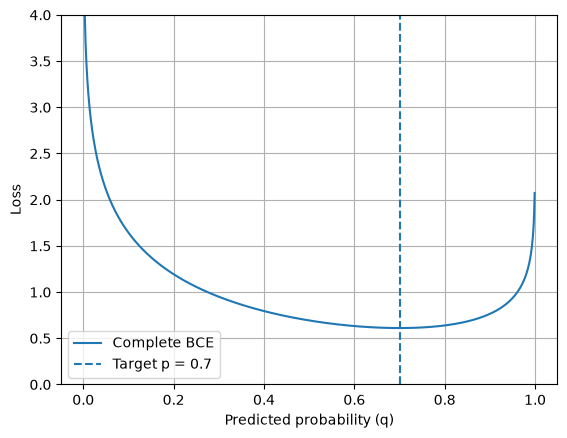

In [ ]:
# This shows only when predicted is equal or closer to the actual the loss is low

import torch
import matplotlib.pyplot as plt

p = torch.tensor(0.7) # actual
q = torch.linspace(0.001, 0.999, 1000) # predicted

# Complete binary cross-entropy
bce_loss = -(p * torch.log(q) + (1-p) * torch.log(1-q))

plt.plot(q, bce_loss, label="BCE")
plt.axvline(0.7, linestyle="--", label="Target p = 0.7")

plt.ylim(0, 4)
plt.xlabel("Predicted probability (q)")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

### Multi Class

This bce gets reduced to -sum(p * log(q))

In [273]:
p = torch.tensor([0, 1, 0])         # Class 1 is correct
q = torch.tensor([0.1, 0.8, 0.1])   # Predicted probabilities
ce_loss = -(p * torch.log(q)).sum()
print(ce_loss)

p = torch.tensor([0, 1, 0])         # Class 1 is correct
q = torch.tensor([0.1, 0.1, 0.8])   # Predicted probabilities
ce_loss = -(p * torch.log(q)).sum()
ce_loss

tensor(0.2231)


tensor(2.3026)

### This we simulate for multiple ranges in predicted prob and see how it changes.

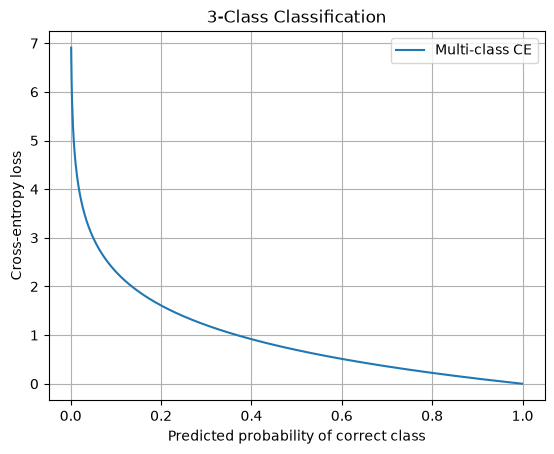

In [274]:
import torch
import matplotlib.pyplot as plt

# Actual target: class 1
p = torch.tensor([0.0, 1.0, 0.0])

# Vary probability of the correct class
q_correct = torch.linspace(0.001, 0.999, 1000)

# Remaining probability distributed equally
q = torch.stack([(1 - q_correct) / 2, q_correct, (1 - q_correct) / 2], dim=1)  # [1000, 3]

# Multi-class cross-entropy
ce_loss = -(p * torch.log(q)).sum(dim=1)

plt.plot(q_correct, ce_loss, label="Multi-class CE")
plt.xlabel("Predicted probability of correct class")
plt.ylabel("Cross-entropy loss")
plt.title("3-Class Classification")
plt.grid()
plt.legend()
plt.show()

Here, class 42 is the correct token. PyTorch applies log-softmax over all 1,000 logits, then calculates the negative log-probability of token 42.

Important insight: For a one-hot target, cross-entropy depends on the probability assigned to the correct class, not on how the remaining probability is distributed among incorrect classes.

In [275]:
logits = torch.randn(1, 1000)
target = torch.tensor([42])

torch.nn.functional.cross_entropy(logits, target)

tensor(6.5891)

In [278]:
target = torch.tensor([0, 1, 0])
prediction_A = torch.tensor([0.1, 0.8, 0.1])
prediction_B = torch.tensor([0.18, 0.8, 0.02])

loss_A = -torch.log(torch.tensor([0.8]))
loss_B = -torch.log(torch.tensor([0.8]))

In [251]:
import torch
import torch.nn.functional as F

a = torch.tensor([1.0, 2.0, 1.0, 3.0])
b = torch.tensor([10.0, 20.0, 10.0, 3.0])
c = torch.tensor([1.2, 2.1, 1.1, 3.1])

# Convert all into probability distributions
p = torch.softmax(a, dim=0)
q = torch.softmax(b, dim=0)
r = torch.softmax(c, dim=0)

# Manual cross entropy: H(P, Q)
manual_b = -(p * torch.log(q)).sum()
manual_c = -(p * torch.log(r)).sum()

# PyTorch: input is logits, target is probabilities
loss_b = F.cross_entropy(b, p)
loss_c = F.cross_entropy(c, p)

print("Manual B:", manual_b.item())
print("PyTorch B:", loss_b.item())

print("Manual C:", manual_c.item())
print("PyTorch C:", loss_c.item())

Manual B: 12.027008056640625
PyTorch B: 12.027008056640625
Manual C: 1.0490946769714355
PyTorch C: 1.0490946769714355


In the below example, the probability is highest for 4th token and its lowest for 1st and 3rd token

We expect loss to be high for 1st and 3rd token if are seen as target, as we should give high loss

In [252]:
logits = torch.tensor([[1.0, 2.0, 1.0, 3.0]])  # sample probability

for i, token in enumerate([0, 1, 2, 3]):
    target = torch.tensor([token])                     
    loss = F.cross_entropy(logits, target)
    print(f"Loss from {i} token - {loss}")

F.cross_entropy(logits, target)

Loss from 0 token - 2.49381160736084
Loss from 1 token - 1.4938117265701294
Loss from 2 token - 2.49381160736084
Loss from 3 token - 0.4938117265701294


tensor(0.4938)

In [253]:
# over batch : you get average loss
logits = torch.tensor([[1.0, 2.0, 1.0, 3.0]])
input_batch = torch.stack((logits, logits)) 

target_1 = torch.tensor([0])
target_2 = torch.tensor([1])
target_batch = torch.stack((target_1, target_2))

total_loss = 0
for idx, batch in enumerate(input_batch):
    loss = F.cross_entropy(batch, target_batch[idx])
    print(f"Batch {idx} loss : {loss}")
    total_loss += loss
avg_loss = total_loss/input_batch.shape[0]
print(f"Avg Loss across the batches : {avg_loss}")

Batch 0 loss : 2.49381160736084
Batch 1 loss : 1.4938117265701294
Avg Loss across the batches : 1.9938116073608398


## GPT Dummy

In [254]:
# inputs
input_tokens = torch.tensor([4, 2, 1, 0])
target_tokens = torch.tensor([2, 1, 0, 3])

# CONSTANTS
vocab_size = 1000
emb_dim = 512
num_heads = 8
head_dim = emb_dim // num_heads
num_layers = 1
context_length = 5 # useful for positions embedding
max_length = len(input_tokens)
ffn_hidden = 100

# embeddings
token_embedding_layer = nn.Embedding(vocab_size, emb_dim) # 1000, 512
token_embedding = token_embedding_layer(input_tokens) # 4, 512

pos_embedding_layer = nn.Embedding(context_length, emb_dim)
positions = torch.arange(len(input_tokens))
pos_embedding = pos_embedding_layer(positions)  # 4, 512

input_embedding = token_embedding + pos_embedding # 4, 512
target_embedding = token_embedding_layer(target_tokens) # 4, 512

# data loader or batch
input_batch = torch.stack((input_embedding, input_embedding))# 2, 4, 512
target_batch = torch.stack((target_embedding, target_embedding)) # 2, 4, 512

# attention
Wk = nn.Linear(emb_dim, emb_dim) # 512, 512
Wq = nn.Linear(emb_dim, emb_dim)
Wv = nn.Linear(emb_dim, emb_dim)

k = Wk(input_batch) # 2, 4, 512
q = Wq(input_batch)
v = Wv(input_batch)

k_exp = k.view(2, 4, num_heads, head_dim) # 2, 4, 8, 64
k_exp = k_exp.view(2, num_heads, 4, head_dim) # 2, 8, 4, 64

q_exp = q.view(2, 4, num_heads, head_dim) 
q_exp = q_exp.view(2, num_heads, 4, head_dim) 

v_exp = v.view(2, 4, num_heads, head_dim) 
v_exp = v_exp.view(2, num_heads, 4, head_dim) 

attn_score = q_exp @ k_exp.transpose(-2, -1) # 2, 8, 4, 4
mask = torch.triu(torch.ones(max_length, max_length), diagonal=1)
attn_score_masked = attn_score.masked_fill(mask.bool(), -torch.inf)
attn_score_masked = torch.softmax(attn_score_masked, dim=-1) # 2, 8, 4, 4

context_vector = attn_score_masked @ v_exp # 2, 8, 4, 64
context_vector = context_vector.contiguous().view(2, max_length, emb_dim) # 2, 4, 512

Wo = nn.Linear(emb_dim, emb_dim)
context_vector_proj = Wo(context_vector) # 2, 4, 512

# layer norm block
layer_norm = nn.LayerNorm(emb_dim)
context_vector_norm = layer_norm(context_vector_proj) # 2, 4, 512

# FFN
Wffn_1 = nn.Linear(emb_dim, ffn_hidden)
Wffn_2 = nn.Linear(ffn_hidden, emb_dim)
context_vector_ffn_hidden = Wffn_1(context_vector_norm) # 2, 4, 100
context_vector_ffn = Wffn_2(context_vector_ffn_hidden) # 2, 4, 512

# layer norm block
context_vector_norm = layer_norm(context_vector_ffn) # 2, 4, 512

# classify
Wclassify = nn.Linear(emb_dim, vocab_size)
classify_output = Wclassify(context_vector_norm) # 2, 4, 1000
probabilities = torch.softmax(classify_output, dim=-1) # 2, 4, 1000
predicted_tokens = torch.argmax(probabilities, dim=-1) # 2, 4

# loss
import torch.nn.functional as F
logits = classify_output[0]  # [4, 1000]
ce_loss = F.cross_entropy(logits, target_tokens)  # [4, 1000] vs [4]
print("Loss:", ce_loss.item())

Loss: 6.985052108764648


In [255]:
import tiktoken
tokenizer  = tiktoken.get_encoding('gpt2')


# inputs
input_text = "How are you"
input_tokens = torch.tensor(tokenizer.encode(input_text))

# CONSTANTS
vocab_size = 50527
emb_dim = 768
num_heads = 8
head_dim = emb_dim // num_heads
num_layers = 1
context_length = 5 # useful for positions embedding
max_length = len(input_tokens)
ffn_hidden = 100

# embeddings
token_embedding_layer = nn.Embedding(vocab_size, emb_dim) # 1000, 512
token_embedding = token_embedding_layer(input_tokens) # 4, 512

pos_embedding_layer = nn.Embedding(context_length, emb_dim)
positions = torch.arange(len(input_tokens))
pos_embedding = pos_embedding_layer(positions)  # 4, 512

input_embedding = token_embedding + pos_embedding # 4, 512

# data loader or batch
input_batch = torch.stack((input_embedding, input_embedding))# 2, 4, 512

# attention
Wk = nn.Linear(emb_dim, emb_dim) # 512, 512
Wq = nn.Linear(emb_dim, emb_dim)
Wv = nn.Linear(emb_dim, emb_dim)

k = Wk(input_batch) # 2, 4, 512
q = Wq(input_batch)
v = Wv(input_batch)

k_exp = k.view(2, len(input_tokens), num_heads, head_dim) # 2, 4, 8, 64
k_exp = k_exp.view(2, num_heads, len(input_tokens), head_dim) # 2, 8, 4, 64

q_exp = q.view(2, len(input_tokens), num_heads, head_dim) 
q_exp = q_exp.view(2, num_heads, len(input_tokens), head_dim) 

v_exp = v.view(2, len(input_tokens), num_heads, head_dim) 
v_exp = v_exp.view(2, num_heads, len(input_tokens), head_dim) 

attn_score = q_exp @ k_exp.transpose(-2, -1) # 2, 8, 4, 4
mask = torch.triu(torch.ones(max_length, max_length), diagonal=1)
attn_score_masked = attn_score.masked_fill(mask.bool(), -torch.inf)
attn_score_masked = torch.softmax(attn_score_masked, dim=-1) # 2, 8, 4, 4

context_vector = attn_score_masked @ v_exp # 2, 8, 4, 64
context_vector = context_vector.contiguous().view(2, max_length, emb_dim) # 2, 4, 512

Wo = nn.Linear(emb_dim, emb_dim)
context_vector_proj = Wo(context_vector) # 2, 4, 512
context_vector_proj.shape


# layer norm block
layer_norm = nn.LayerNorm(emb_dim)
context_vector_norm = layer_norm(context_vector_proj) # 2, 4, 512

# FFN
Wffn_1 = nn.Linear(emb_dim, ffn_hidden)
Wffn_2 = nn.Linear(ffn_hidden, emb_dim)
context_vector_ffn_hidden = Wffn_1(context_vector_norm) # 2, 4, 100
context_vector_ffn = Wffn_2(context_vector_ffn_hidden) # 2, 4, 512

# layer norm block
context_vector_norm = layer_norm(context_vector_ffn) # 2, 4, 512

# classify
Wclassify = nn.Linear(emb_dim, vocab_size)
classify_output = Wclassify(context_vector_norm) # 2, 4, 1000
probabilities = torch.softmax(classify_output, dim=-1) # 2, 4, 1000
predicted_tokens = torch.argmax(probabilities, dim=-1) # 2, 4
predicted = tokenizer.decode(predicted_tokens[0].tolist())
predicted

' demonstrationszon Catherine'

## 8. Temperature Scaling

1. Multinomial alters the distribution
2. Instead of argmax which always picks only one, multinomial gives other tokens a change too.
3. Check last plot, when temperature is increasd the prob distibutions gets kind of uniform giving other tokens a fair chance
4. This happens because high temperature shrinks the value and the difference between the logits, implies the softmax gets closer and uniform.

Original:        [2,    4,    6]       Difference = 4

Temperature 10:  [0.2,  0.4,  0.6]     Difference = 0.4

Temperature 100: [0.02, 0.04, 0.06]    Difference = 0.04

In [256]:
vocab = {
    "how" : 0,
    "are" : 1,
    "you" : 2,
    "doing" : 3,
    "today" : 4,
    "welcome" : 5,
    "to" : 6,
    "USA" : 7
}
inverse_vocab = {v:k for k, v in vocab.items()}

In [257]:
# Assume you say - how are
next_token_logits = torch.tensor(
    [4.51, 0.89, 10.90, 6.75, 1.63, -1.62, -1.89, 6.28]
)
prob = torch.softmax(next_token_logits, dim=0)
next_token = torch.argmax(prob).item()
print(inverse_vocab[next_token])

you


In [258]:
next_token = torch.multinomial(prob, num_samples=1).item()
print(inverse_vocab[next_token])

you


In [259]:
def print_sampled_tokens(probas):
    torch.manual_seed(123)
    sample = [torch.multinomial(prob, num_samples=1).item()
             for i in range(1_000)]
    sampled_ids = torch.bincount(torch.tensor(sample))
    for i, freq in enumerate(sampled_ids):
        print(f"{freq} = {inverse_vocab[i]}")

print_sampled_tokens(prob)

0 = how
0 = are
985 = you
5 = doing
0 = today
0 = welcome
0 = to
10 = USA


### Notice the important change in argmax to multinomial

torch.argmax(prob)	 = Same highest-logit token every time

torch.multinomial(prob, 1)	= More diverse token selections

torch.multinomial(prob, 1) with low temperature	 = Strong preference for highest-logit token


In [260]:
def softmax_temp(logits, temperature):
    scaled_logits = logits/temperature
    return torch.softmax(scaled_logits, dim=0)
next_token_logits = torch.tensor(
    [4.51, 0.89, 10.90, 6.75, 1.63, -1.62, -1.89, 6.28]
)
prob = softmax_temp(next_token_logits, temperature=0.1)
next_token = torch.multinomial(prob, num_samples=1).item() 
print(inverse_vocab[next_token])

you


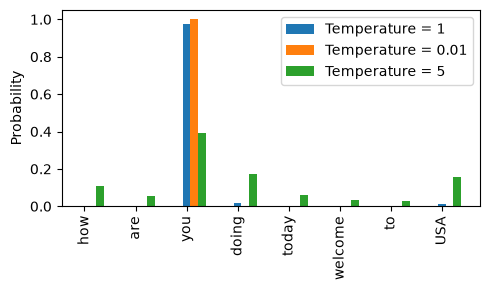

In [261]:
import matplotlib.pyplot as plt
temperatures = [1, 0.01, 5]                                     #1
scaled_probas = [softmax_temp(next_token_logits, T)
                for T in temperatures]
x = torch.arange(len(vocab))
bar_width = 0.15
fig, ax = plt.subplots(figsize=(5, 3))
for i, T in enumerate(temperatures):
    rects = ax.bar(x + i * bar_width, scaled_probas[i], 
                   bar_width, label=f'Temperature = {T}')
ax.set_ylabel('Probability')
ax.set_xticks(x)
ax.set_xticklabels(vocab.keys(), rotation=90)
ax.legend()
plt.tight_layout()
plt.show()